# Attention and a Transformer From Scratch

The RNN/LSTM notebooks read a sequence one step at a time and squeeze everything into a hidden state. **Attention** lets every position look directly at every other position. A Transformer is attention plus a few supporting pieces.

Built here, each piece checked against PyTorch's own implementation:

1. **Scaled dot-product attention**: the core formula
2. **Masks**: ignore padding; block the future (causal)
3. **Multi-head attention**: several attention patterns in parallel
4. **Positional encoding**: attention alone has no sense of order
5. **Transformer encoder block** and a small **text classifier**
6. **Train** on 4 newsgroups, then **inspect** the attention weights

> Prereq: `02_lstm_text_classification.ipynb` (embeddings, padding, the classifier setup).

In [1]:
import math, re, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

random.seed(0); np.random.seed(0); torch.manual_seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)

device: cpu


## 1. Scaled dot-product attention

Every token makes three vectors: a **query** Q ("what am I looking for?"), a **key** K ("what do I contain?") and a **value** V ("what do I hand over if chosen?").

$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

- `Q @ K^T` scores every query against every key: shape `[T, T]`
- softmax turns each row into weights that sum to 1
- the output is a weighted average of the values
- dividing by `sqrt(d_k)` keeps scores from growing with dimension, which would saturate softmax (see the check below)

In [2]:
def attention(q, k, v, mask=None):
    """q,k,v: [..., T, d]. mask: broadcastable to [..., Tq, Tk]; False = blocked."""
    d_k = q.size(-1)
    scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)   # [..., Tq, Tk]
    if mask is not None:
        scores = scores.masked_fill(~mask, float('-inf'))
    weights = scores.softmax(dim=-1)
    return weights @ v, weights

q = torch.randn(2, 5, 16); k = torch.randn(2, 5, 16); v = torch.randn(2, 5, 16)
out, w = attention(q, k, v)
ref = F.scaled_dot_product_attention(q, k, v)
print('out shape      :', tuple(out.shape), ' weights:', tuple(w.shape))
print('rows sum to 1  :', torch.allclose(w.sum(-1), torch.ones(2, 5)))
print('matches PyTorch:', torch.allclose(out, ref, atol=1e-6))

out shape      : (2, 5, 16)  weights: (2, 5, 5)
rows sum to 1  : True
matches PyTorch: True


### Why divide by `sqrt(d_k)`?

If q and k have unit-variance entries, `q . k` has variance `d_k`. Large scores push softmax toward one-hot, where gradients vanish.

In [3]:
for d in [4, 64, 1024]:
    q = torch.randn(1000, d); k = torch.randn(1000, d)
    raw = (q * k).sum(-1)
    print(f'd_k={d:5d}  std of q.k = {raw.std():7.2f}   after /sqrt(d_k) = {(raw / math.sqrt(d)).std():.2f}')

d_k=    4  std of q.k =    1.93   after /sqrt(d_k) = 0.97
d_k=   64  std of q.k =    8.10   after /sqrt(d_k) = 1.01
d_k= 1024  std of q.k =   31.48   after /sqrt(d_k) = 0.98


## 2. Masks

**Padding mask**: padded positions carry no information, so no one should attend to them. **Causal mask**: for language generation, position `t` may only see positions `<= t`.

Blocked scores are set to `-inf` before softmax, which gives them weight exactly 0.

In [4]:
T = 5
causal = torch.tril(torch.ones(T, T, dtype=torch.bool))          # lower triangle = allowed
_, w_causal = attention(torch.randn(1, T, 8), torch.randn(1, T, 8), torch.randn(1, T, 8), mask=causal)
print('causal weights (row = query, col = key):')
print(w_causal[0].round(decimals=2))

lengths = torch.tensor([5, 3])                                   # 2nd sequence has 2 pads
pad = (torch.arange(T)[None, :] < lengths[:, None])              # [B, T] True = real token
_, w_pad = attention(torch.randn(2, T, 8), torch.randn(2, T, 8), torch.randn(2, T, 8),
                     mask=pad[:, None, :])                       # broadcast over queries
print('\nweight on padded keys (seq 2, cols 3-4):', w_pad[1, :, 3:].abs().max().item())

causal weights (row = query, col = key):
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4600, 0.5400, 0.0000, 0.0000, 0.0000],
        [0.4600, 0.3400, 0.2000, 0.0000, 0.0000],
        [0.2100, 0.2500, 0.2900, 0.2500, 0.0000],
        [0.0600, 0.1200, 0.3500, 0.1800, 0.2900]])

weight on padded keys (seq 2, cols 3-4): 0.0


## 3. Multi-head attention

One attention pattern is limiting. **Multi-head** attention projects into `h` smaller subspaces (`d_head = d_model / h`), runs attention in each, concatenates, and mixes with a final linear layer. Different heads can learn different relations (nearby words, same topic, etc.).

Implementation trick: one big `Linear` for Q/K/V, then reshape `[B, T, d_model] -> [B, h, T, d_head]`.

In [5]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_head = n_heads, d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.out = nn.Linear(d_model, d_model)

    def forward(self, x, mask=None, return_weights=False):
        B, T, D = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        split = lambda t: t.view(B, T, self.h, self.d_head).transpose(1, 2)   # [B,h,T,dh]
        q, k, v = split(q), split(k), split(v)
        if mask is not None and mask.dim() == 2:          # [B,T] padding mask -> [B,1,1,T]
            mask = mask[:, None, None, :]
        y, w = attention(q, k, v, mask)
        y = y.transpose(1, 2).reshape(B, T, D)           # concat heads
        y = self.out(y)
        return (y, w) if return_weights else y

# Check against nn.MultiheadAttention by copying weights across
d_model, h = 32, 4
mine = MultiHeadAttention(d_model, h)
ref  = nn.MultiheadAttention(d_model, h, batch_first=True)
with torch.no_grad():
    ref.in_proj_weight.copy_(mine.qkv.weight); ref.in_proj_bias.copy_(mine.qkv.bias)
    ref.out_proj.weight.copy_(mine.out.weight); ref.out_proj.bias.copy_(mine.out.bias)
x = torch.randn(2, 7, d_model)
print('matches nn.MultiheadAttention:', torch.allclose(mine(x), ref(x, x, x, need_weights=False)[0], atol=1e-5))

matches nn.MultiheadAttention: True


## 4. Positional encoding

Attention treats its input as a *set*: shuffle the tokens and each token's output is the same, just reordered. Order must be injected. The original paper adds fixed sine/cosine waves of different frequencies to the embeddings:

$$PE_{(pos,2i)}=\sin\!\left(\frac{pos}{10000^{2i/d}}\right),\qquad PE_{(pos,2i+1)}=\cos\!\left(\frac{pos}{10000^{2i/d}}\right)$$

Learned position embeddings (`nn.Embedding(max_len, d)`) work about as well; sinusoids need no parameters.

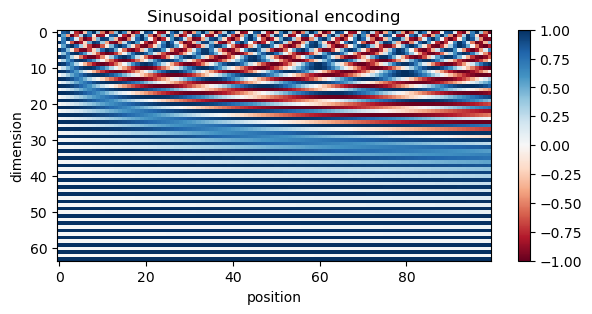

permuting input just permutes output (no order info): True


In [6]:
def sinusoidal_pe(max_len, d_model):
    pos = torch.arange(max_len)[:, None]
    i = torch.arange(0, d_model, 2)[None, :]
    angle = pos / (10000 ** (i / d_model))
    pe = torch.zeros(max_len, d_model)
    pe[:, 0::2], pe[:, 1::2] = angle.sin(), angle.cos()
    return pe

pe = sinusoidal_pe(100, 64)
plt.figure(figsize=(7, 3)); plt.imshow(pe.T, cmap='RdBu', aspect='auto')
plt.xlabel('position'); plt.ylabel('dimension'); plt.colorbar(); plt.title('Sinusoidal positional encoding'); plt.show()

# demo: without PE, attention is permutation-equivariant
mha = MultiHeadAttention(32, 4).eval()
x = torch.randn(1, 6, 32); perm = torch.randperm(6)
print('permuting input just permutes output (no order info):',
      torch.allclose(mha(x)[:, perm], mha(x[:, perm]), atol=1e-5))

## 5. The Transformer encoder block

```
x -> LayerNorm -> MultiHeadAttention -> + x  (residual)
  -> LayerNorm -> FeedForward (Linear, GELU, Linear) -> + (residual)
```

- **Residual connections** let gradients flow straight through deep stacks.
- **LayerNorm** normalizes each token's features (unlike BatchNorm, no batch statistics, so it works with any batch size and sequence length).
- **Feed-forward** processes each position independently; attention mixes positions, the FFN mixes features.
- This is the *pre-LN* layout, which trains more stably than the original post-LN.

In [7]:
class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask=None, return_weights=False):
        a, w = self.attn(self.ln1(x), mask, return_weights=True)
        x = x + self.drop(a)
        x = x + self.drop(self.ff(self.ln2(x)))
        return (x, w) if return_weights else x

class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, n_classes, d_model=64, n_heads=4, d_ff=128,
                 n_layers=2, max_len=128, dropout=0.1):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.register_buffer('pe', sinusoidal_pe(max_len, d_model))
        self.blocks = nn.ModuleList(EncoderBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_layers))
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, n_classes)
        self.scale = math.sqrt(d_model)

    def forward(self, ids, return_weights=False):
        mask = ids != 0                                        # [B,T] True = real token
        x = self.emb(ids) * self.scale + self.pe[:ids.size(1)]
        ws = []
        for blk in self.blocks:
            x, w = blk(x, mask, return_weights=True); ws.append(w)
        x = self.ln(x)
        m = mask.unsqueeze(-1).float()
        pooled = (x * m).sum(1) / m.sum(1).clamp(min=1)         # masked mean pool
        logits = self.head(pooled)
        return (logits, ws) if return_weights else logits

**Pooling:** a classifier needs one vector per document. Here: mean over real tokens (padding masked out). BERT instead prepends a special `[CLS]` token and reads its output.

## 6. Data: 4 newsgroups

A small, fast subset: 4 categories, first 128 tokens, vocabulary capped at the 5000 most common words.

In [8]:
cats = ['rec.sport.hockey', 'sci.space', 'comp.graphics', 'talk.politics.guns']
ng = fetch_20newsgroups(subset='all', categories=cats, remove=('headers', 'footers', 'quotes'))
tokenize = lambda t: re.sub(r'[^a-z0-9\s]', '', t.lower()).split()

counts = Counter(tok for t in ng.data for tok in tokenize(t))
vocab = {'<PAD>': 0, '<UNK>': 1}
for w, _ in counts.most_common(4998): vocab[w] = len(vocab)

MAX_LEN = 128
def encode(text):
    ids = ([vocab.get(t, 1) for t in tokenize(text)] or [1])[:MAX_LEN]
    return ids + [0] * (MAX_LEN - len(ids))

X = torch.tensor([encode(t) for t in ng.data]); y = torch.tensor(ng.target)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=64, shuffle=True)
print(f'{len(X)} docs, vocab {len(vocab)}, train {len(Xtr)}, test {len(Xte)}')

3869 docs, vocab 5000, train 3095, test 774


## 7. Train

Transformers are touchy about optimization: **AdamW**, a small learning rate, and gradient clipping. (Large models also add LR warmup.)

Expect roughly 75-80% test accuracy, with train loss falling much faster than test accuracy rises (overfitting; see `03_regularization`). A from-scratch Transformer on ~3k documents does not beat a bag-of-words baseline: Transformers earn their keep with large data or pretraining, not on tiny datasets.

In [9]:
model = TransformerClassifier(len(vocab), len(cats)).to(DEVICE)
print(f'params: {sum(p.numel() for p in model.parameters()):,}')
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)

def evaluate():
    model.eval()
    with torch.no_grad():
        return (model(Xte.to(DEVICE)).argmax(1).cpu() == yte).float().mean().item()

for epoch in range(8):
    model.train(); tot = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        opt.zero_grad()
        loss = F.cross_entropy(model(xb), yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); tot += loss.item() * len(xb)
    print(f'epoch {epoch+1}  train_loss {tot/len(Xtr):.3f}  test_acc {evaluate():.3f}')

params: 387,332


epoch 1  train_loss 1.374  test_acc 0.425


epoch 2  train_loss 1.268  test_acc 0.541


epoch 3  train_loss 0.969  test_acc 0.619


epoch 4  train_loss 0.746  test_acc 0.699


epoch 5  train_loss 0.584  test_acc 0.731


epoch 6  train_loss 0.455  test_acc 0.751


epoch 7  train_loss 0.343  test_acc 0.774


epoch 8  train_loss 0.259  test_acc 0.791


## 8. Look inside: attention weights

Attention weights are a built-in diagnostic: row `i` shows where token `i` looked. Caveat: weights show *where information flowed*, not a guaranteed explanation of the prediction.

true: sci.space | predicted: sci.space


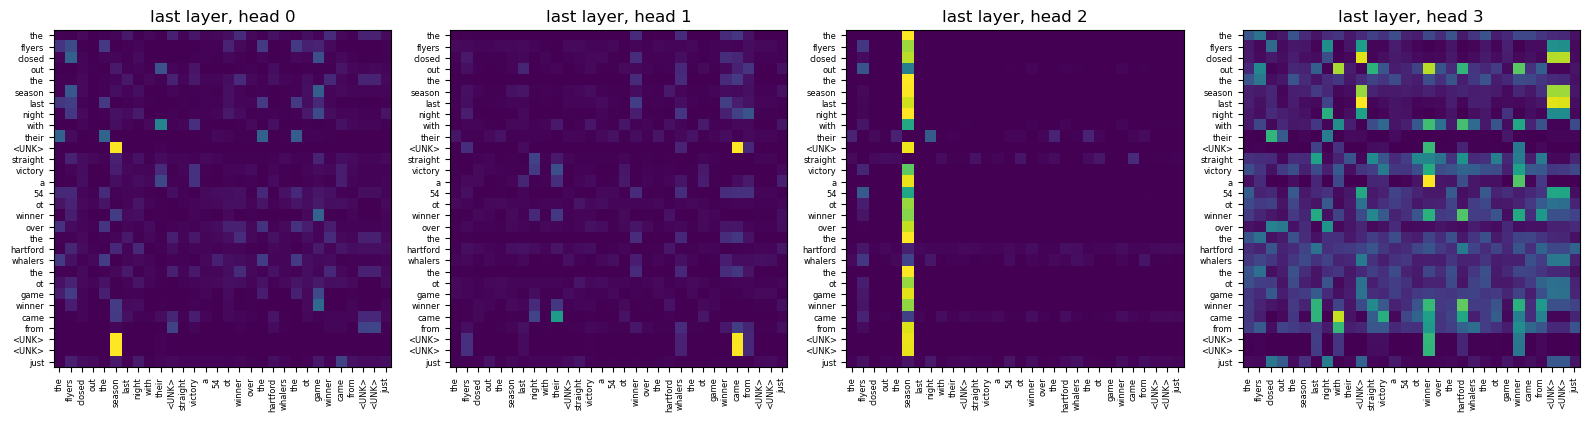

In [10]:
model.eval()
i = int((yte == 1).nonzero()[0])                        # a sci.space test doc
ids = Xte[i:i+1].to(DEVICE)
with torch.no_grad():
    logits, ws = model(ids, return_weights=True)
inv = {v: k for k, v in vocab.items()}
n = int((ids != 0).sum())
toks = [inv[t] for t in ids[0, :n].tolist()][:30]
print('true:', cats[yte[i]], '| predicted:', cats[logits.argmax().item()])

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for h, ax in enumerate(axes):
    ax.imshow(ws[-1][0, h, :30, :30].cpu(), cmap='viridis')
    ax.set_title(f'last layer, head {h}')
    ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks, rotation=90, fontsize=6)
    ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks, fontsize=6)
plt.tight_layout(); plt.show()

## 9. Where this goes

| Piece | Here | Full-size models |
|---|---|---|
| Encoder-only (this notebook) | classify, embed | BERT |
| Decoder-only (add the **causal mask**) | next-token prediction | GPT |
| Encoder + decoder (add **cross-attention**: Q from decoder, K/V from encoder) | translation | original Transformer, T5 |
| Position info | sinusoidal | learned, RoPE |
| Scale | ~0.4M params | 10^8 to 10^12 |

Attention cost is `O(T^2)` in sequence length: the `[T, T]` score matrix is why long contexts are expensive.

**Compared with the LSTM notebook:** no recurrence, so all positions compute in parallel and distant tokens connect in one step instead of through many hidden-state updates. The price is quadratic memory and the need for explicit position information.

## Exercises
1. Remove the positional encoding and compare accuracy. How much does word order matter for topic classification?
2. Add a causal mask in `EncoderBlock` and train a character-level next-token model.
3. Swap mean-pooling for a prepended `[CLS]` token.
4. Try `n_heads=1` vs `8` at constant `d_model`.